# 01 資料與前處理:載入、EDA、特徵、切分

In [1]:
import os, sys, warnings
from pathlib import Path

root = Path.cwd()
while not (root / "src").exists() and root != root.parent:
    root = root.parent
os.chdir(root); sys.path.insert(0, str(root))
print("project root:", root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.preprocessing import (
    DATA_PATH, SPLIT_PATH, DROP_COLS, CONSTANT_COLS, ID_COLS, NOMINAL_COLS,
    DERIVED_COLS, RANDOM_STATE, load_raw, split_xy, make_train_test_split,
    age_group, FeatureEngineer, make_preprocessor,
)

sns.set_theme(style="whitegrid")
FIG = Path("reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 50)

project root: C:\Users\USER\data_science_final_project


## 檢查缺失值、常數欄位、識別碼

In [2]:
df = load_raw()

In [3]:
print("缺失值總數:", int(df.isna().sum().sum()))
nun = df.nunique()
print("常數欄位:", nun[nun == 1].index.tolist())
print("疑似識別碼(每列都不同):", nun[nun == len(df)].index.tolist())
print("重複列數:", int(df.duplicated().sum()))
print()
print(df.dtypes.value_counts())

缺失值總數: 0
常數欄位: ['EmployeeCount', 'Over18', 'StandardHours']
疑似識別碼(每列都不同): ['EmployeeNumber']
重複列數: 0

int64    26
str       9
Name: count, dtype: int64


## 移除常數欄位與 EmployeeNumber, 切分測試集

- remove `EmployeeCount`、`Over18`、`StandardHours`(const)、`EmployeeNumber`(index)
- split train/test set (80/20) ,`random_state=42`, save to  `data/split_indices.csv`

In [4]:
X, y = split_xy(df)
print("after removing:", X.shape, "| dropped:", DROP_COLS)

X_train, X_test, y_train, y_test = make_train_test_split(X, y) 
print("train:", X_train.shape, f"ratio {y_train.mean():.3f}")
print("test :", X_test.shape,  f"ratio {y_test.mean():.3f}")

after removing: (1470, 30) | dropped: ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber']
train: (1176, 30) ratio 0.162
test : (294, 30) ratio 0.160


## EDA
training set only

### 目標分布與欄位分布

數值欄位 23 個,類別欄位 7 個: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


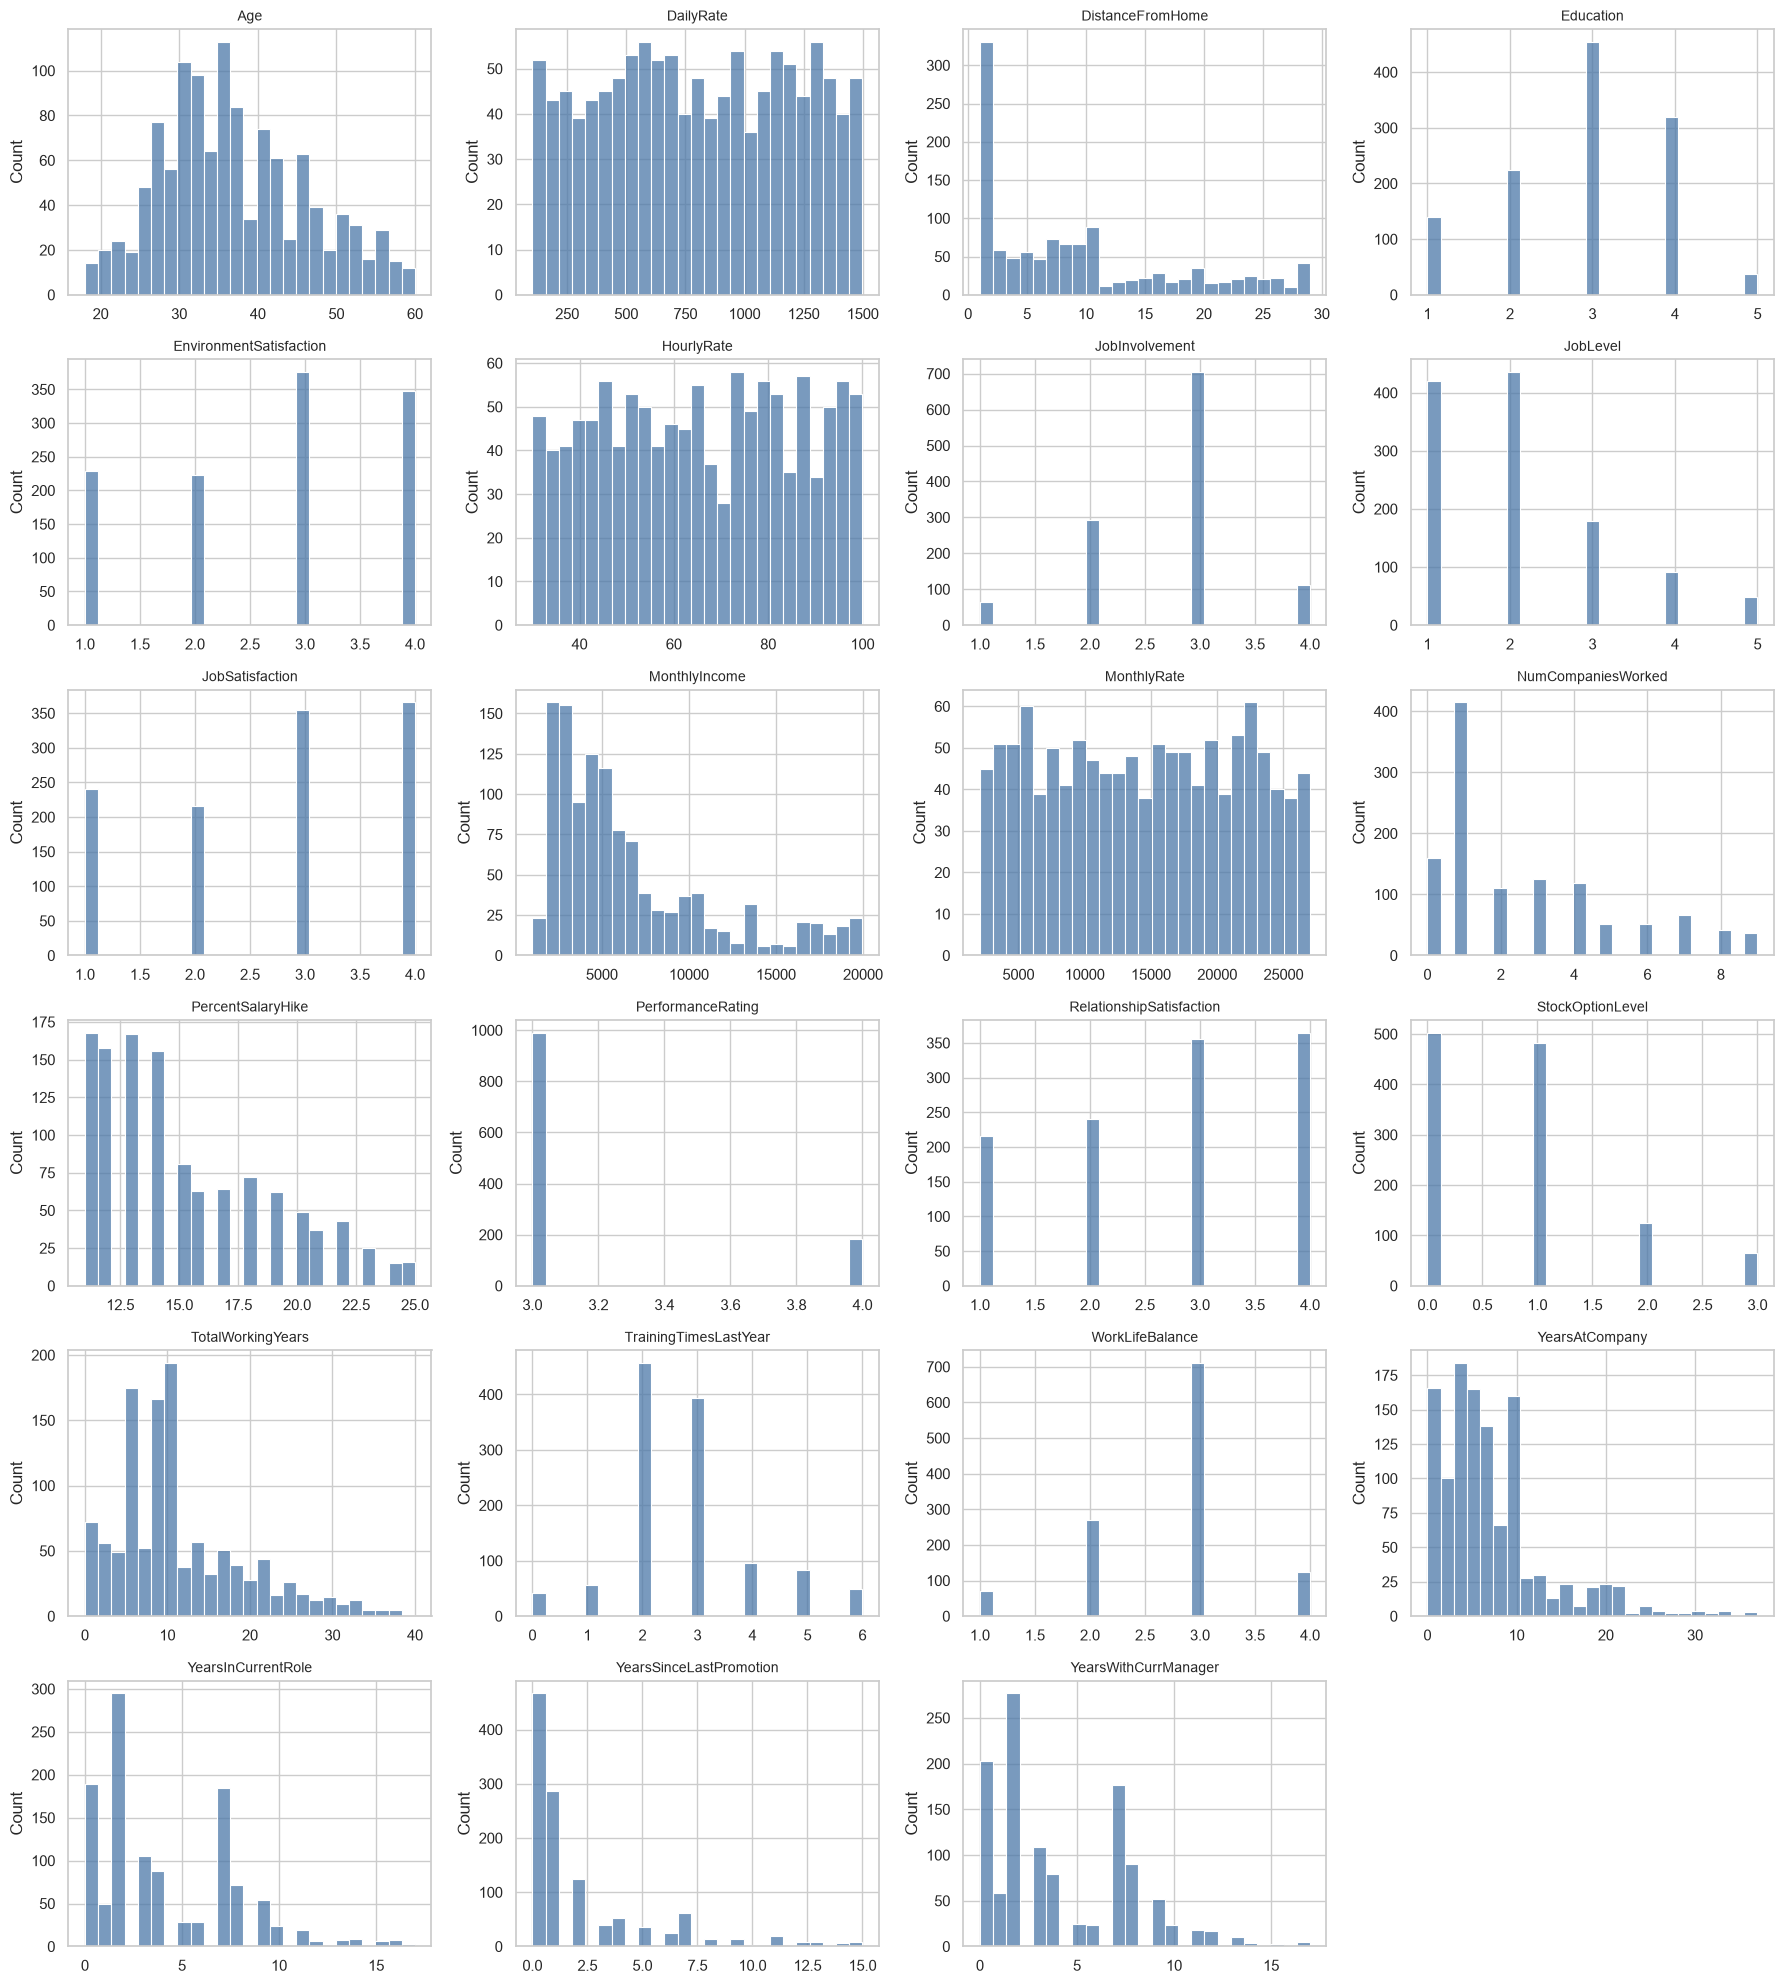

In [5]:
train = X_train.copy(); train["Attrition"] = y_train

num_cols = X_train.select_dtypes("number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist() 
print(f"數值欄位 {len(num_cols)} 個,類別欄位 {len(cat_cols)} 個:", cat_cols)

fig, axes = plt.subplots(6, 4, figsize=(18, 20))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(train[c], ax=ax, bins=25, color="#4c78a8")
    ax.set_title(c, fontsize=10)
    ax.set_xlabel("")

for ax in axes.ravel()[len(num_cols):]: ax.axis("off")

plt.tight_layout()
plt.savefig(FIG / "numeric_distributions.png", dpi=120)
plt.show()

### long tail detection

In [6]:
skew = train[num_cols].skew().sort_values(ascending=False)
skew_tbl = skew.to_frame("skew")
display(skew_tbl.head(12))
print("偏態較高的數值特徵僅供觀察，模型不進行 log 轉換。")

,skew
YearsSinceLastPromotion,1.970864
PerformanceRating,1.884807
YearsAtCompany,1.732897
MonthlyIncome,1.332950
TotalWorkingYears,1.103707
NumCompaniesWorked,0.999071
JobLevel,0.979308
StockOptionLevel,0.969760
DistanceFromHome,0.928220
YearsInCurrentRole,0.872928


偏態較高的數值特徵僅供觀察，模型不進行 log 轉換。


### 離職 vs. 留任:數值特徵差異
找出可能影響離職的特徵

0: "Stay (median)", 1: "Leave (median)"

Attrition,Stay (median),Leave (median),diff %
StockOptionLevel,1.0,0.0,-100.0
JobLevel,2.0,1.0,-50.0
YearsAtCompany,6.0,3.0,-50.0
NumCompaniesWorked,2.0,1.0,-50.0
MonthlyIncome,5237.5,3373.0,-35.6
YearsInCurrentRole,3.0,2.0,-33.3
TrainingTimesLastYear,3.0,2.0,-33.3
YearsWithCurrManager,3.0,2.0,-33.3
TotalWorkingYears,10.0,7.0,-30.0
DistanceFromHome,7.0,9.0,28.6


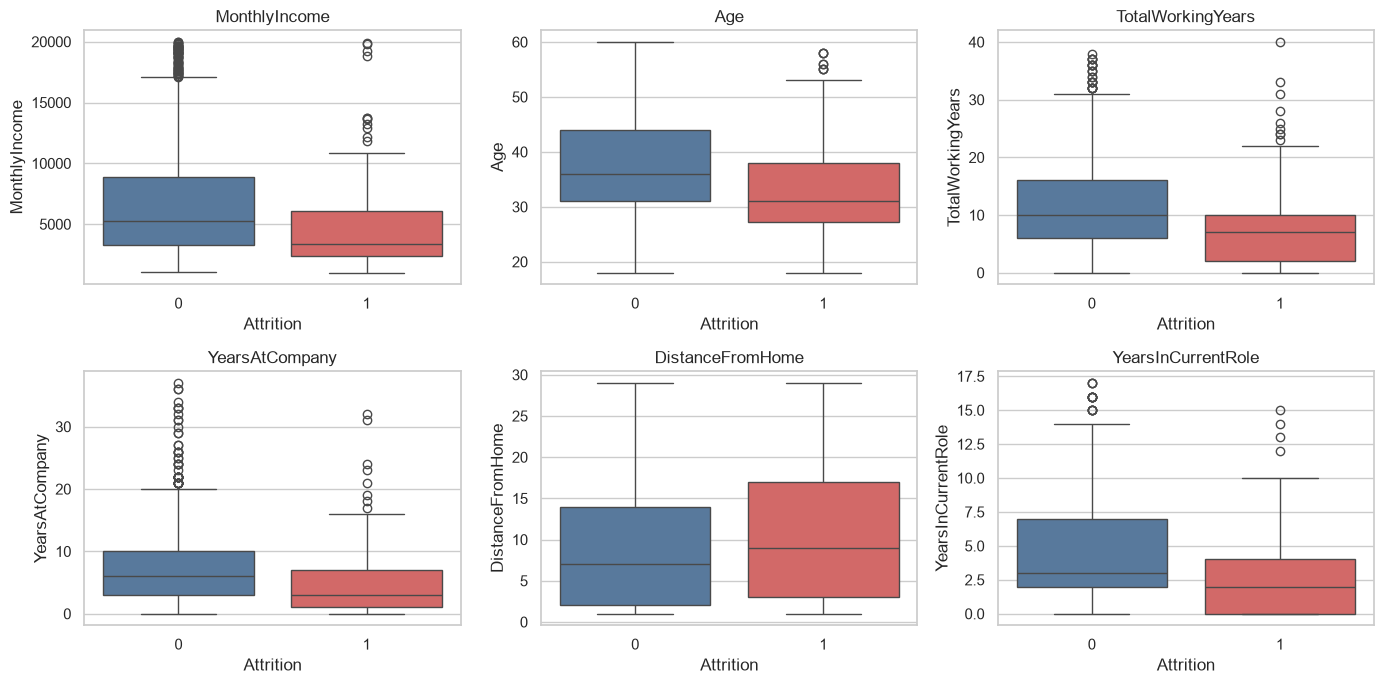

In [7]:
cmp = train.groupby("Attrition")[num_cols].median().T.rename(columns={0: "Stay (median)", 1: "Leave (median)"})
cmp["diff %"] = ((cmp["Leave (median)"] - cmp["Stay (median)"]) / cmp["Stay (median)"].replace(0, np.nan) * 100).round(1)
display(cmp.sort_values("diff %", key=abs, ascending=False).head(12))

show = ["MonthlyIncome", "Age", "TotalWorkingYears", "YearsAtCompany", "DistanceFromHome", "YearsInCurrentRole"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), show):
    sns.boxplot(data=train, x="Attrition", y=c, hue="Attrition", legend=False, ax=ax, palette=["#4c78a8", "#e45756"]); ax.set_title(c)

plt.tight_layout()
plt.savefig(FIG / "numeric_by_attrition.png", dpi=150)
plt.show()


- **離職者整體較年輕**：年齡中位數為 31 歲，留任者為 36 歲。
- **離職者薪資較低**：MonthlyIncome 中位數約 3,373，留任者約 5,238。
- **離職者年資較短**：TotalWorkingYears、YearsAtCompany、YearsInCurrentRole 的中位數皆低於留任者。
- **離職者職級較低**：JobLevel 中位數為 1，留任者為 2。
- **離職者通勤距離較遠**：DistanceFromHome 中位數為 9，留任者為 7。
- 各組資料仍有明顯重疊，因此這些特徵只能表示**相關性，不能直接推論因果關係**。

整體而言，圖表顯示「年輕、低薪、年資較短、職級較低，以及通勤距離較遠」可能與較高離職風險相關。

### 各類別特徵的離職率

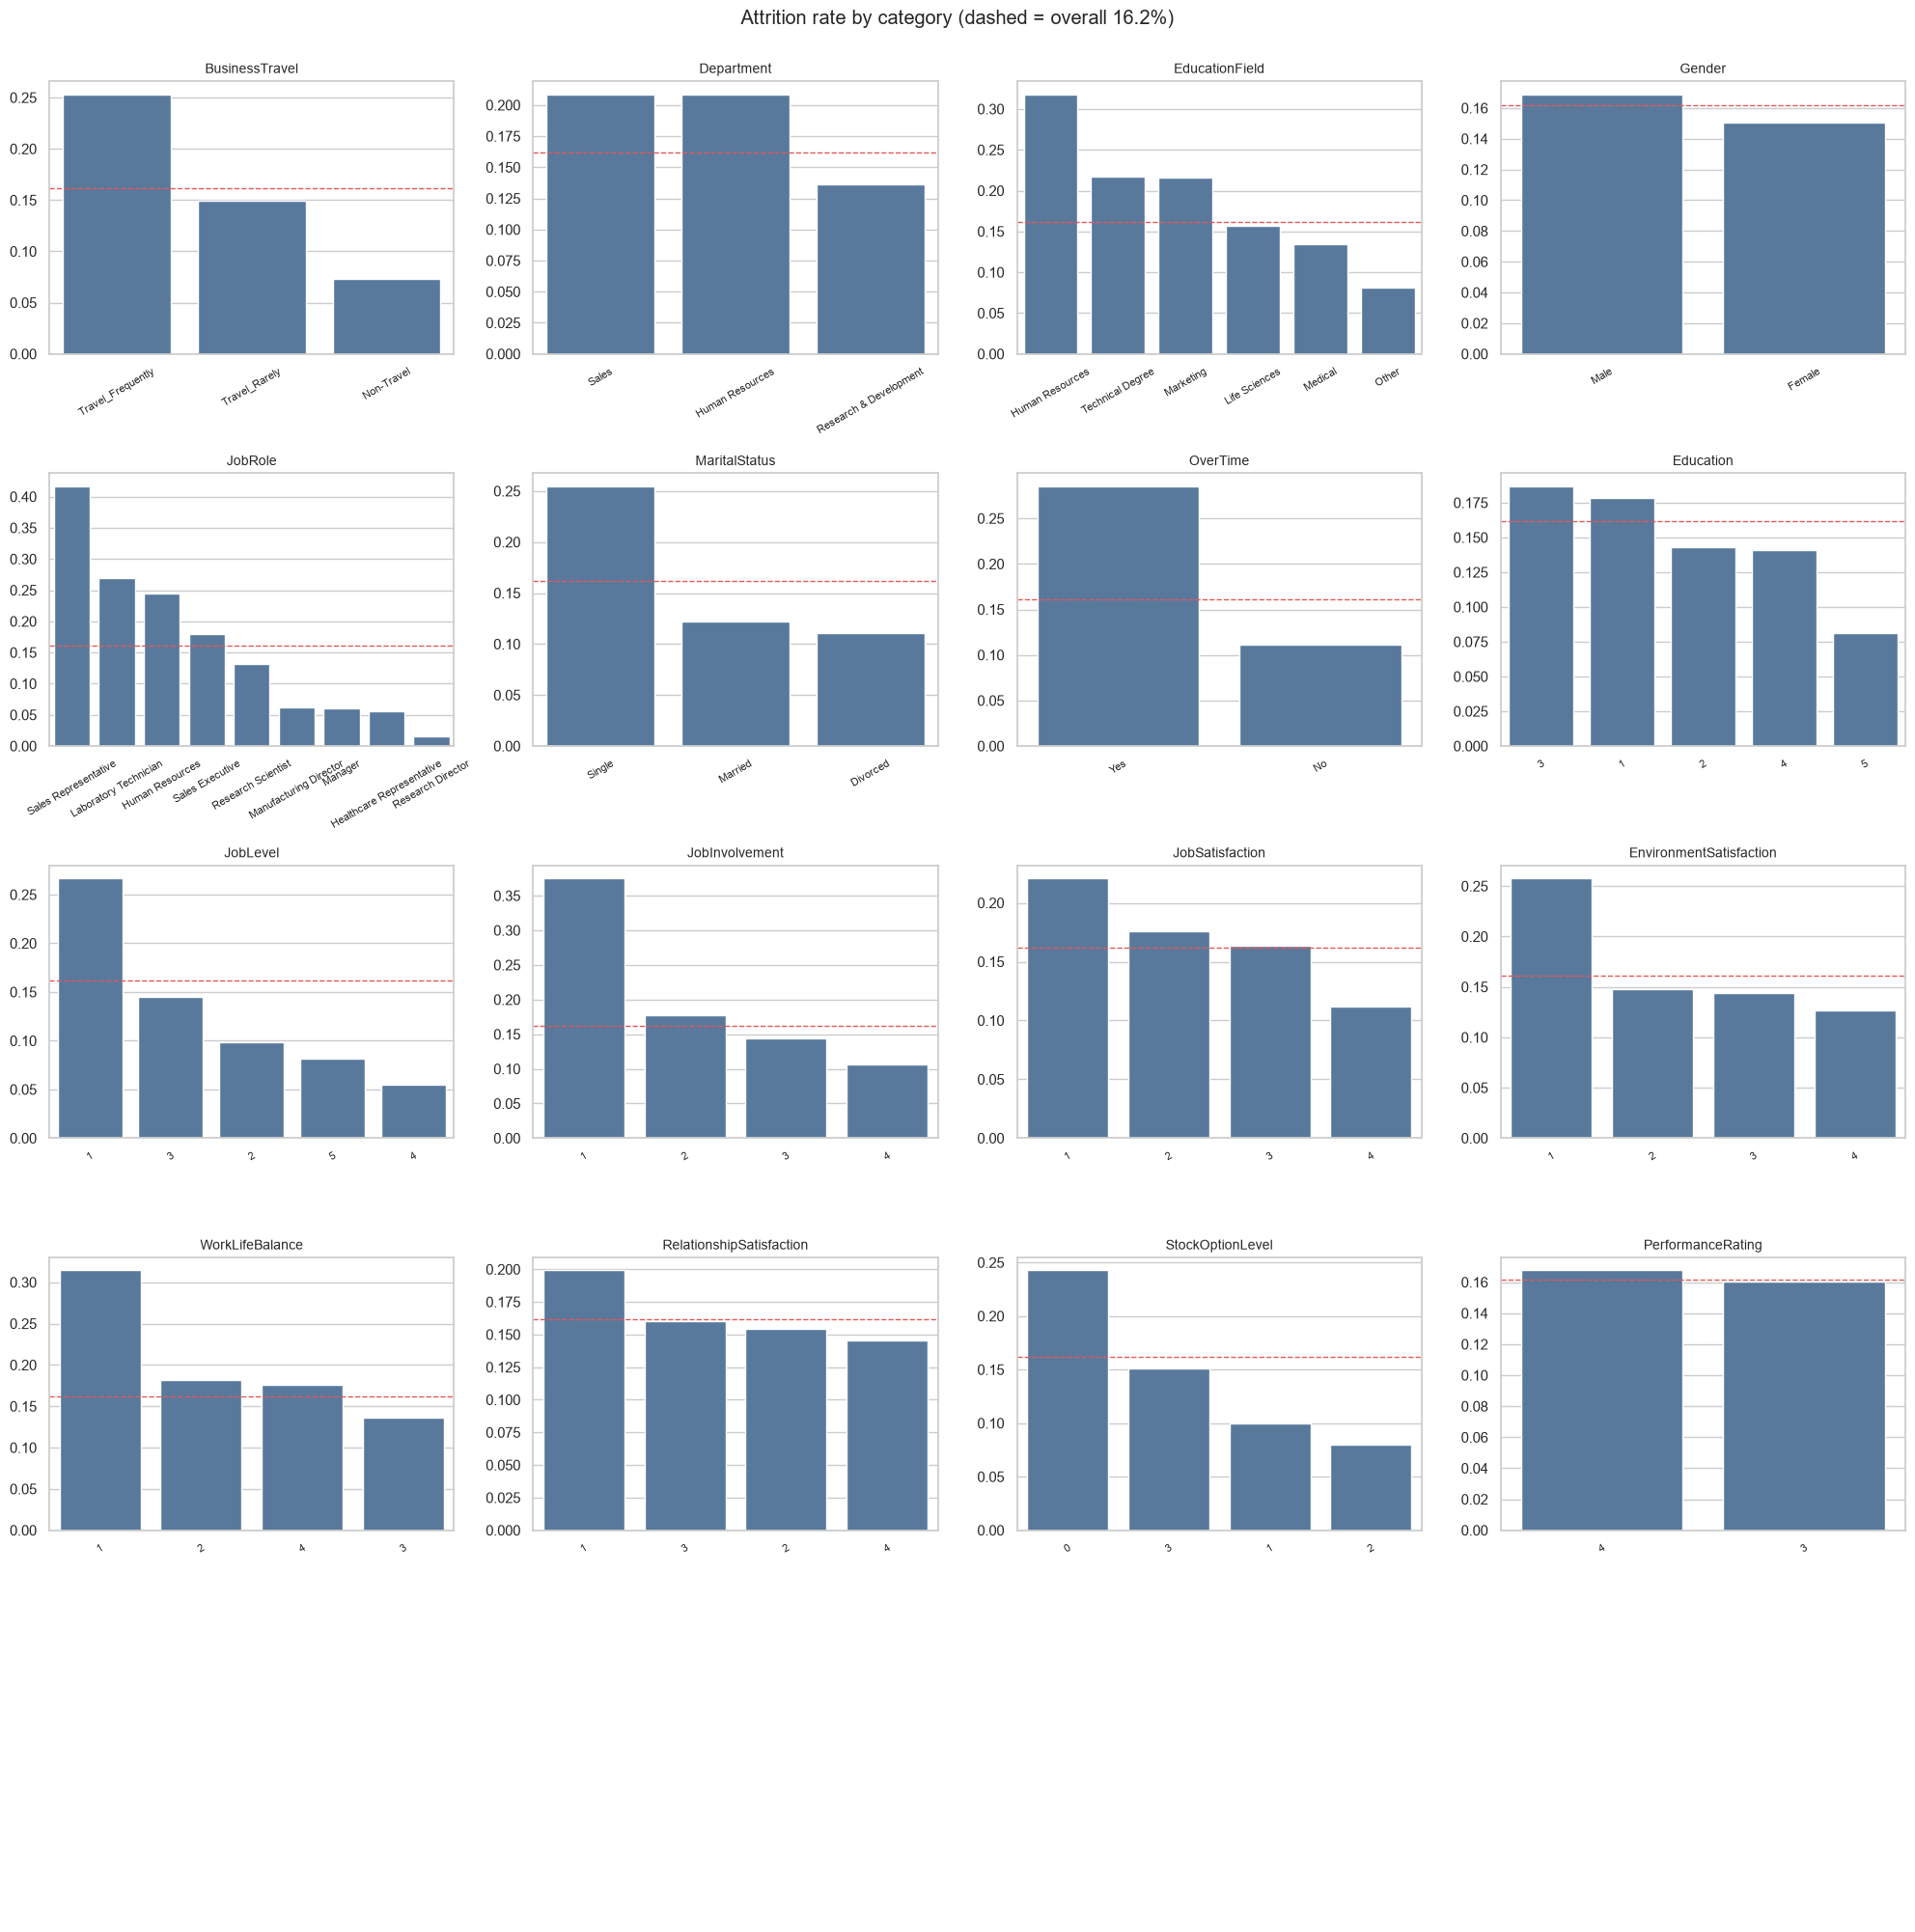

           mean  count
OverTime              
No        0.111    836
Yes       0.285    340 

                    mean  count
BusinessTravel                 
Non-Travel         0.073    123
Travel_Frequently  0.253    225
Travel_Rarely      0.150    828 

                mean  count
MaritalStatus              
Divorced       0.110    263
Married        0.122    540
Single         0.255    373 



In [8]:
ordinal_like = ["Education", "JobLevel", "JobInvolvement", "JobSatisfaction", "EnvironmentSatisfaction",
                "WorkLifeBalance", "RelationshipSatisfaction", "StockOptionLevel", "PerformanceRating"]
rate_cols = cat_cols + ordinal_like
overall = y_train.mean()

fig, axes = plt.subplots(5, 4, figsize=(20, 20))
for ax, c in zip(axes.ravel(), rate_cols):
    r = train.groupby(c)["Attrition"].mean().sort_values(ascending=False)
    sns.barplot(x=r.index.astype(str), y=r.values, ax=ax, color="#4c78a8")
    ax.axhline(overall, color="#e45756", ls="--", lw=1); ax.set_title(c, fontsize=10)
    ax.tick_params(axis="x", rotation=30, labelsize=8); ax.set_xlabel("")
for ax in axes.ravel()[len(rate_cols):]: ax.axis("off")

plt.suptitle(f"Attrition rate by category (dashed = overall {overall:.1%})", y=1.0)
plt.tight_layout()
plt.savefig(FIG / "attrition_rate_by_category.png", dpi=120)
plt.show()

for c in ["OverTime", "BusinessTravel", "MaritalStatus"]:
    print(train.groupby(c)["Attrition"].agg(["mean", "count"]).round(3), "\n")

- 比較教育程度、職級、工作投入、工作滿意度、環境滿意度、工作生活平衡、關係滿意度、股票選擇權、績效評等，以及其他類別特徵在不同群組下的離職率。
- 在各項特徵中，加班、出差頻率與婚姻狀況的組別差異較明顯，因此列為主要觀察結果。
- 加班員工的離職率為 28.5%，高於未加班員工的 11.1%；經常出差員工的離職率最高，為 25.3%；未婚員工的離職率為 25.5%，也高於已婚及離婚員工。
- 整體而言，加班、頻繁出差及未婚身分可能與較高離職風險相關；其他特徵仍需搭配統計檢定與模型結果進一步判斷。以上結果僅代表關聯性，不能直接推論因果關係。

### 4.5 相關性與多重共線性

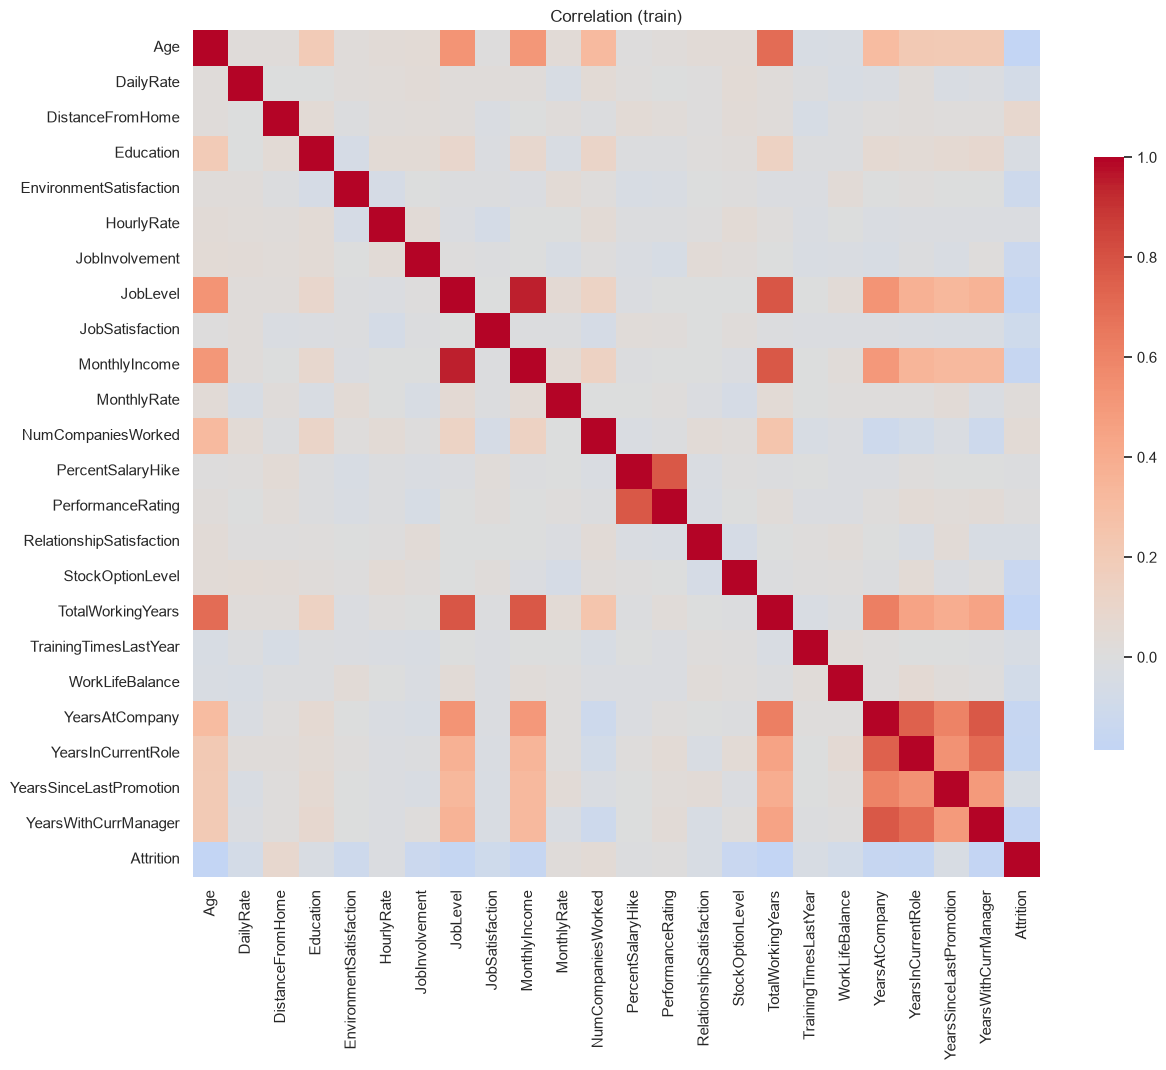

與離職最相關的數值特徵:


,corr
TotalWorkingYears,-0.186
Age,-0.185
YearsWithCurrManager,-0.169
YearsInCurrentRole,-0.167
JobLevel,-0.166
MonthlyIncome,-0.160
YearsAtCompany,-0.155
StockOptionLevel,-0.143
JobInvolvement,-0.125
EnvironmentSatisfaction,-0.113


,feature_a,feature_b,corr
170,JobLevel,MonthlyIncome,0.947008
177,JobLevel,TotalWorkingYears,0.785244
459,YearsAtCompany,YearsWithCurrManager,0.776416
223,MonthlyIncome,TotalWorkingYears,0.774830
289,PercentSalaryHike,PerformanceRating,0.773922
457,YearsAtCompany,YearsInCurrentRole,0.747264
482,YearsInCurrentRole,YearsWithCurrManager,0.706864


In [9]:
corr = train[num_cols + ["Attrition"]].corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, square=True, cbar_kws={"shrink": .7})
plt.title("Correlation (train)")
plt.savefig(FIG / "correlation.png", dpi=150, bbox_inches="tight")
plt.show()

print("與離職最相關的數值特徵:")
display(corr["Attrition"].drop("Attrition").sort_values(key=abs, ascending=False).head(10).round(3).to_frame("corr"))

pairs = (corr.drop(columns="Attrition").drop(index="Attrition").where(np.triu(np.ones((len(num_cols),) * 2), 1).astype(bool))
         .stack().rename("corr").reset_index())
display(pairs[pairs["corr"].abs() > 0.7].sort_values("corr", key=abs, ascending=False)
        .rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))

## 編碼與數值轉換方式

| 欄位 | 處理 | 理由 |
|---|---|---|
| `Department`、`EducationField`、`JobRole`、`MaritalStatus`、`Gender` | One-hot(`handle_unknown="ignore"`) | 無序類別 |
| `BusinessTravel` | 有序編碼 Non-Travel=0 < Travel_Rarely=1 < Travel_Frequently=2 | 有明確順序 |
| `OverTime` | Yes=1 / No=0 | 二元 |
| `Education`、`JobLevel`、各項滿意度、`StockOptionLevel` 等 | 保留原本的整數(當有序數值) | 資料本身已是有序整數編碼 |
| 線性模型的數值欄位 | 不做 log 轉換，直接標準化(平均、標準差只用訓練折) | 保留原始數值尺度與可解釋性 |
| 樹模型(DT/RF/XGB/LGBM) | 不做 log 與標準化 | 不需要 |

**特徵設定：** `Gender`、`Age` 皆放進模型；數值特徵不進行 log 轉換。

## 衍生特徵

同職級平均月薪(來自訓練集):


,mean MonthlyIncome
JobLevel,
1,2786.0
2,5532.0
3,9789.0
4,15476.0
5,19142.0


                     mean    std    min    max
salary_ratio        1.000  0.238  0.362  1.807
stagnation          0.288  0.340  0.000  1.000
workload            0.324  0.580  0.000  2.000
satisfaction_score  2.731  0.572  1.000  4.000
Attrition           0.162  0.368  0.000  1.000

衍生特徵與離職的相關:


,corr
salary_ratio,-0.090
stagnation,0.024
workload,0.225
satisfaction_score,-0.172


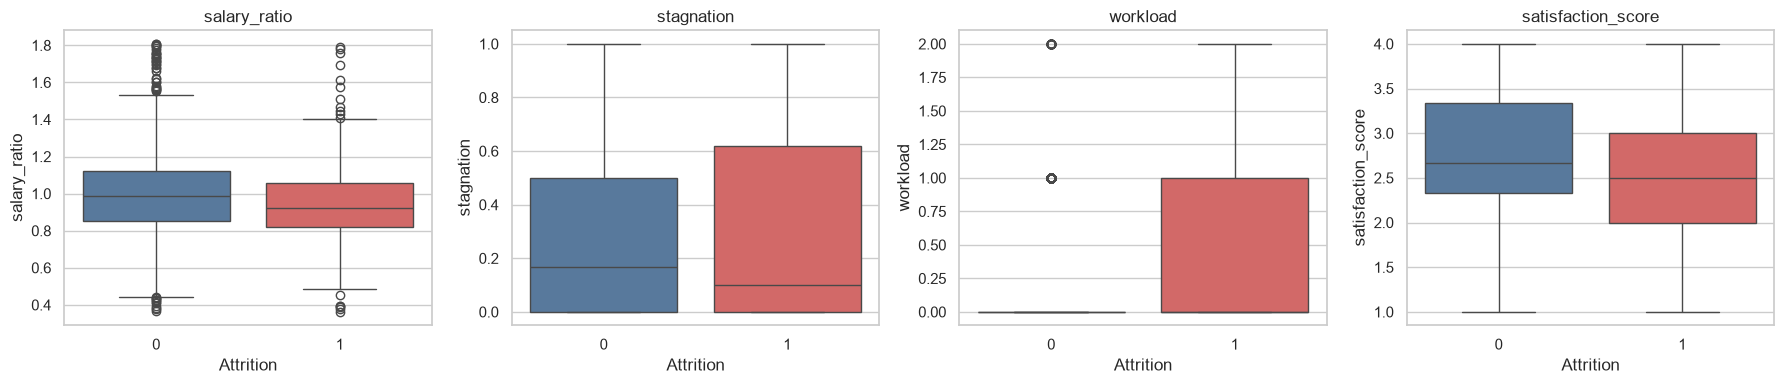

In [10]:
fe = FeatureEngineer().fit(X_train)            
print("同職級平均月薪(來自訓練集):"); display(fe.level_mean_.round(0).to_frame("mean MonthlyIncome"))

feat_train = fe.transform(X_train)
chk = feat_train[DERIVED_COLS].copy(); chk["Attrition"] = y_train
print(chk.describe().round(3).T[["mean", "std", "min", "max"]])
print("\n衍生特徵與離職的相關:"); display(chk.corr()["Attrition"].drop("Attrition").round(3).to_frame("corr"))

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, DERIVED_COLS):
    sns.boxplot(data=chk, x="Attrition", y=c, hue="Attrition", legend=False, ax=ax, palette=["#4c78a8", "#e45756"]); ax.set_title(c)
plt.tight_layout(); plt.savefig(FIG / "derived_features.png", dpi=150); plt.show()

## 組成 Pipeline 並確認輸出

In [11]:
lin = make_preprocessor("linear").fit(X_train, y_train)
tre = make_preprocessor("tree").fit(X_train, y_train)

for name, p in [("linear", lin), ("tree", tre)]:
    Ztr, Zte = p.transform(X_train), p.transform(X_test)
    assert list(Ztr.columns) == list(Zte.columns)
    assert np.isfinite(Ztr.to_numpy()).all() and np.isfinite(Zte.to_numpy()).all()
    print(f"{name:6s}: train {Ztr.shape}, test {Zte.shape}")

lin.transform(X_train).iloc[:, :8].describe().round(2).T[["mean", "std"]]   # 訓練集標準化後應接近 0 / 1

linear: train (1176, 52), test (294, 52)
tree  : train (1176, 52), test (294, 52)


,mean,std
Department_Human Resources,0.04,0.20
Department_Research & Development,0.65,0.48
Department_Sales,0.31,0.46
EducationField_Human Resources,0.02,0.14
EducationField_Life Sciences,0.41,0.49
EducationField_Marketing,0.11,0.32
EducationField_Medical,0.31,0.46
EducationField_Other,0.05,0.22


年輕、低薪、低職級、年資較短、通勤距離較遠